In [11]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

np.random.seed(42)
categorias = ['Electrónica', 'Accesorios', 'Computación', 'Hogar']
productos = {
    'Electrónica': ['Smart TV 55"', 'Barra de Sonido', 'Audífonos Bluetooth'],
    'Accesorios': ['Mouse Inalámbrico', 'Teclado Mecánico', 'Cable HDMI'],
    'Computación': ['Laptop HP', 'Monitor 24"', 'Disco Duro 1TB'],
    'Hogar': ['Cafetera', 'Licuadora', 'Aspiradora']
}
ciudades = ['Bogotá', 'Medellín', 'Cali', 'Barranquilla', 'Cartagena']

data = []
for i in range(500):
    fecha = datetime(2026, 1, 1) + timedelta(days=np.random.randint(0, 180))
    categoria = np.random.choice(categorias)
    producto = np.random.choice(productos[categoria])
    ciudad = np.random.choice(ciudades)
    cantidad = np.random.randint(1, 10)
    
    if categoria == 'Computación': precio_base = 1500000
    elif categoria == 'Electrónica': precio_base = 800000
    elif categoria == 'Hogar': precio_base = 200000
    else: precio_base = 50000
    
    precio = precio_base + np.random.randint(-50000, 50000)
    costo = precio * 0.7 
    data.append([i+1, fecha.strftime('%d/%m/%Y'), ciudad, categoria, producto, cantidad, precio, costo])

df = pd.DataFrame(data, columns=['id_venta', 'fecha', 'ciudad', 'categoria', 'producto', 'cantidad', 'precio_unitario', 'costo_unitario'])

# Inyectar errores a propósito para demostrar limpieza
df.loc[10, 'precio_unitario'] = np.nan 
df.loc[20, 'ciudad'] = np.nan 
df.loc[30, 'fecha'] = '2026-13-45' 
df = pd.concat([df, df.iloc[[50, 60]]]) 

df.to_csv('ventas_techmarket.csv', index=False)
print("Archivo 'ventas_techmarket.csv' creado con éxito en la carpeta del proyecto.")

Archivo 'ventas_techmarket.csv' creado con éxito en la carpeta del proyecto.


In [12]:
!pip install pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- 1. CARGA Y EXPLORACIÓN ---")
df = pd.read_csv('ventas_techmarket.csv')
print(df.head())
print("\nInformación del Dataset:")
print(df.info())

print("\nEstadísticas Básicas:")
print(df.describe(include='all'))

--- 1. CARGA Y EXPLORACIÓN ---
   id_venta       fecha        ciudad   categoria           producto  \
0         1  13/04/2026          Cali       Hogar           Cafetera   
1         2  13/04/2026          Cali  Accesorios         Cable HDMI   
2         3  14/04/2026     Cartagena       Hogar         Aspiradora   
3         4  07/06/2026  Barranquilla  Accesorios   Teclado Mecánico   
4         5  27/02/2026  Barranquilla  Accesorios  Mouse Inalámbrico   

   cantidad  precio_unitario  costo_unitario  
0         8         226820.0        158774.0  
1         8          44131.0         30891.7  
2         2         209735.0        146814.5  
3         5          83104.0         58172.8  
4         9          25658.0         17960.6  

Información del Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_venta         502 non-null    int64

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- 1. CARGA Y EXPLORACIÓN ---")
df = pd.read_csv('ventas_techmarket.csv')
print(df.head())
print("\nInformación del Dataset:")
print(df.info())
print("\nEstadísticas Básicas:")
print(df.describe())

--- 1. CARGA Y EXPLORACIÓN ---
   id_venta       fecha        ciudad   categoria           producto  \
0         1  13/04/2026          Cali       Hogar           Cafetera   
1         2  13/04/2026          Cali  Accesorios         Cable HDMI   
2         3  14/04/2026     Cartagena       Hogar         Aspiradora   
3         4  07/06/2026  Barranquilla  Accesorios   Teclado Mecánico   
4         5  27/02/2026  Barranquilla  Accesorios  Mouse Inalámbrico   

   cantidad  precio_unitario  costo_unitario  
0         8         226820.0        158774.0  
1         8          44131.0         30891.7  
2         2         209735.0        146814.5  
3         5          83104.0         58172.8  
4         9          25658.0         17960.6  

Información del Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_venta         502 non-null    int64

In [15]:
print("\n--- 2. LIMPIEZA DE DATOS ---")
# a. Eliminar duplicados
df = df.drop_duplicates(subset=['id_venta'])
print(f"Registros después de eliminar duplicados: {len(df)}")

# b. Manejo de valores nulos
df['precio_unitario'] = df['precio_unitario'].fillna(df['precio_unitario'].mean())
df['ciudad'] = df['ciudad'].fillna('Desconocido')

# c. Conversión de fechas
df['fecha'] = pd.to_datetime(df['fecha'], format='%d/%m/%Y', errors='coerce')
df = df.dropna(subset=['fecha'])

# Crear columna de mes con nombre en español
meses_es = {1:'Enero', 2:'Febrero', 3:'Marzo', 4:'Abril', 5:'Mayo', 6:'Junio', 7:'Julio', 8:'Agosto', 9:'Septiembre', 10:'Octubre', 11:'Noviembre', 12:'Diciembre'}
df['mes'] = df['fecha'].dt.month.map(meses_es)

print("Datos limpios correctamente.")


--- 2. LIMPIEZA DE DATOS ---
Registros después de eliminar duplicados: 500
Datos limpios correctamente.


In [16]:
# Cálculo de nuevas columnas
df['total_venta'] = df['cantidad'] * df['precio_unitario']
df['ganancia'] = df['total_venta'] - (df['cantidad'] * df['costo_unitario'])
print("\nNuevas columnas calculadas con éxito.")

print("\n--- 3. MODELO ESTRELLA ---")
# Tabla de Hechos
hechos_ventas = df[['id_venta', 'fecha', 'ciudad', 'categoria', 'producto', 'cantidad', 'total_venta', 'ganancia']].copy()
# Tablas de Dimensiones
dim_productos = df[['producto', 'categoria']].drop_duplicates().reset_index(drop=True)
dim_ciudades = df[['ciudad']].drop_duplicates().reset_index(drop=True)

print("Tabla de Hechos (ventas):", hechos_ventas.shape)
print("Dimensión Productos:", dim_productos.shape)
print("Dimensión Ciudades:", dim_ciudades.shape)


Nuevas columnas calculadas con éxito.

--- 3. MODELO ESTRELLA ---
Tabla de Hechos (ventas): (499, 8)
Dimensión Productos: (12, 2)
Dimensión Ciudades: (6, 1)


In [17]:
print("\n--- 4. KPIs ---")
ventas_totales = df['total_venta'].sum()
promedio_venta = df['total_venta'].mean()
producto_mas_vendido = df.groupby('producto')['cantidad'].sum().idxmax()
mes_mayores_ventas = df.groupby('mes')['total_venta'].sum().idxmax()

print(f"Ventas Totales: ${ventas_totales:,.2f}")
print(f"Promedio por Venta: ${promedio_venta:,.2f}")
print(f"Producto más vendido: {producto_mas_vendido}")
print(f"Mes con mayores ventas: {mes_mayores_ventas}")


--- 4. KPIs ---
Ventas Totales: $1,575,188,806.95
Promedio por Venta: $3,156,691.00
Producto más vendido: Barra de Sonido
Mes con mayores ventas: Enero



--- 5. GENERANDO DASHBOARD ---


C:\Windows\Temp\ipykernel_3548\1136115463.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_productos.values, y=top_productos.index, ax=axes[0, 1], palette='viridis')
C:\Windows\Temp\ipykernel_3548\1136115463.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ventas_ciudad.index, y=ventas_ciudad.values, ax=axes[1, 1], palette='magma')


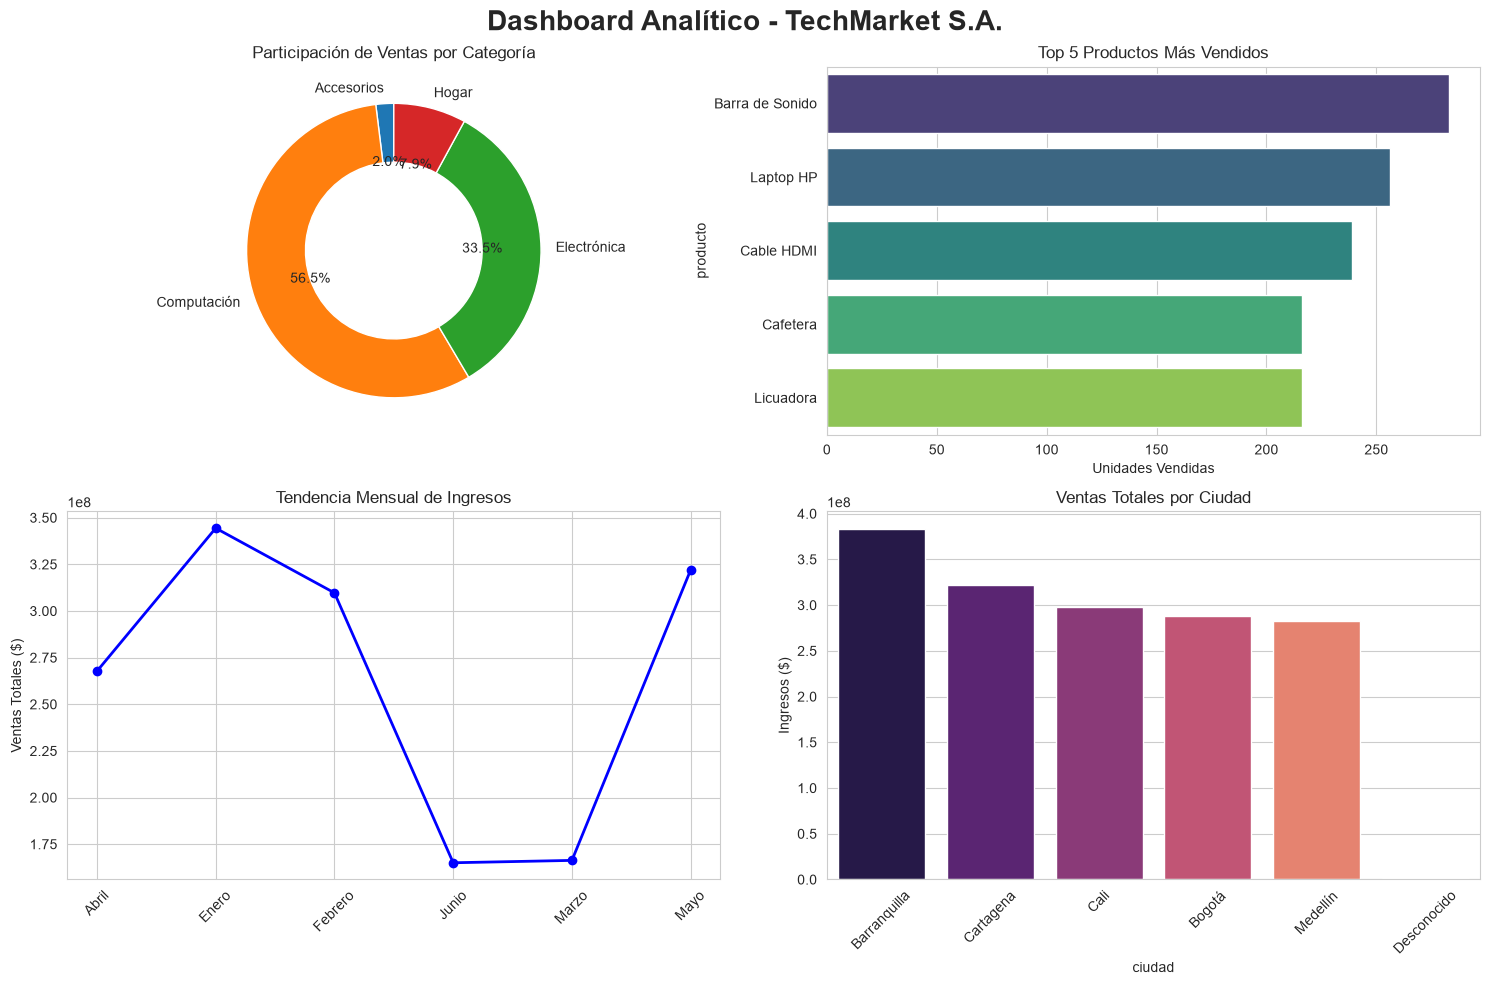


Dashboard exportado como 'dashboard_techmarket.png'


In [18]:
print("\n--- 5. GENERANDO DASHBOARD ---")
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Dashboard Analítico - TechMarket S.A.', fontsize=20, fontweight='bold')

# Gráfico 1: Anillo (Participación por Categoría)
ventas_categoria = df.groupby('categoria')['total_venta'].sum()
axes[0, 0].pie(ventas_categoria, labels=ventas_categoria.index, autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=0.4))
axes[0, 0].set_title('Participación de Ventas por Categoría')

# Gráfico 2: Barras (Top 5 Productos)
top_productos = df.groupby('producto')['cantidad'].sum().nlargest(5)
sns.barplot(x=top_productos.values, y=top_productos.index, ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('Top 5 Productos Más Vendidos')
axes[0, 1].set_xlabel('Unidades Vendidas')

# Gráfico 3: Líneas (Tendencia Mensual)
tendencia_mensual = df.groupby('mes')['total_venta'].sum()
axes[1, 0].plot(tendencia_mensual.index, tendencia_mensual.values, marker='o', color='b', linewidth=2)
axes[1, 0].set_title('Tendencia Mensual de Ingresos')
axes[1, 0].set_ylabel('Ventas Totales ($)')
axes[1, 0].tick_params(axis='x', rotation=45)

# Gráfico 4: Barras (Ventas por Ciudad)
ventas_ciudad = df.groupby('ciudad')['total_venta'].sum().sort_values(ascending=False)
sns.barplot(x=ventas_ciudad.index, y=ventas_ciudad.values, ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('Ventas Totales por Ciudad')
axes[1, 1].set_ylabel('Ingresos ($)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('dashboard_techmarket.png', dpi=300)
plt.show()
print("\nDashboard exportado como 'dashboard_techmarket.png'")